# Module 19 — Exercises — Solutions

These exercises follow the order of the concept guide: returns and discounting, bandit algorithms, exact
policy evaluation, Bellman operators and value iteration, model-free learning (TD, Monte Carlo, SARSA,
Q-learning), the score-function gradient, and finally a mini-project that pits dynamic programming,
Q-learning and REINFORCE against each other on the same gridworld. The setup cell defines a small
`GridWorld` class (with an explicit model `P[s, a, s']`, `R[s, a]` and a sampling `step`) and a 4-state MDP
`P4, R4` that several exercises share. Several checks compare against *hidden* values, so compute rather
than guess.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)


class GridWorld:
    # A small gridworld with an explicit model P[s, a, s'], R[s, a] and a sampling step().
    # Actions: 0 up, 1 right, 2 down, 3 left. With probability `slip` the move goes sideways
    # (half each way). Bumping into a wall or the border leaves the agent where it is.
    # Entering the goal gives goal_reward, a pit pit_reward, any other move step_reward; goal and pits are terminal.
    ACTIONS = np.array([(-1, 0), (0, 1), (1, 0), (0, -1)])
    ARROWS = ["^", ">", "v", "<"]

    def __init__(self, n_rows, n_cols, start, goal, walls=(), pits=(), slip=0.0,
                 step_reward=-1.0, goal_reward=10.0, pit_reward=-10.0, gamma=0.9):
        self.n_rows, self.n_cols = n_rows, n_cols
        self.n_states, self.n_actions = n_rows * n_cols, 4
        self.start, self.goal = self.idx(*start), self.idx(*goal)
        self.walls = {self.idx(*w) for w in walls}
        self.pits = {self.idx(*p) for p in pits}
        self.terminal = {self.goal} | self.pits
        self.slip, self.step_reward, self.goal_reward, self.pit_reward, self.gamma = slip, step_reward, goal_reward, pit_reward, gamma
        self.P, self.R = self._build_model()
        self.cumP = self.P.cumsum(axis=2)

    def idx(self, r, c): return r * self.n_cols + c
    def rc(self, s): return divmod(s, self.n_cols)

    def _move(self, s, a):
        r, c = self.rc(s); dr, dc = self.ACTIONS[a]; r2, c2 = r + dr, c + dc
        if not (0 <= r2 < self.n_rows and 0 <= c2 < self.n_cols) or self.idx(r2, c2) in self.walls:
            return s
        return self.idx(r2, c2)

    def _reward(self, s2):
        if s2 == self.goal: return self.goal_reward
        if s2 in self.pits: return self.pit_reward
        return self.step_reward

    def _build_model(self):
        S, A = self.n_states, self.n_actions
        P = np.zeros((S, A, S)); R = np.zeros((S, A))
        for s in range(S):
            if s in self.terminal or s in self.walls:
                P[s, :, s] = 1.0; continue
            for a in range(A):
                outcomes = {a: 1.0 - self.slip, (a - 1) % 4: self.slip / 2, (a + 1) % 4: self.slip / 2}
                for a2, prob in outcomes.items():
                    if prob == 0: continue
                    s2 = self._move(s, a2)
                    P[s, a, s2] += prob; R[s, a] += prob * self._reward(s2)
        return P, R

    def step(self, s, a, rng):
        # sample s' ~ P(. | s, a); returns (s', reward, done)
        s2 = int(np.searchsorted(self.cumP[s, a], rng.random()))
        return s2, self._reward(s2), s2 in self.terminal

    def policy_string(self, policy):
        # arrows for non-terminal, non-wall states, '.' elsewhere; row by row
        return "".join("." if (s in self.terminal or s in self.walls) else self.ARROWS[int(policy[s])] for s in range(self.n_states))


# the gridworld used in Exercises 6, 8 and the mini-project
grid = GridWorld(4, 4, start=(3, 0), goal=(0, 3), walls=[(1, 1), (2, 2)], pits=[(0, 2)], slip=0.1, gamma=0.95)

# a 4-state, 2-action MDP used in Exercises 4 and 5 (P4[s, a, s'], R4[s, a])
P4 = np.zeros((4, 2, 4))
P4[0, 0] = [0.5, 0.5, 0.0, 0.0];  P4[0, 1] = [0.0, 0.0, 1.0, 0.0]
P4[1, 0] = [0.0, 0.2, 0.8, 0.0];  P4[1, 1] = [0.6, 0.0, 0.0, 0.4]
P4[2, 0] = [0.0, 0.0, 0.0, 1.0];  P4[2, 1] = [0.3, 0.3, 0.4, 0.0]
P4[3, 0] = [1.0, 0.0, 0.0, 0.0];  P4[3, 1] = [0.0, 0.0, 0.0, 1.0]
R4 = np.array([[1.0, 0.0], [2.0, -1.0], [0.0, 3.0], [-2.0, 0.5]])

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Discounted returns  `★☆☆`

Implement

* `discounted_return(rewards, gamma)` — the return $G_0 = \sum_{k \ge 0} \gamma^k r_{k+1}$ of a finite reward sequence (a Python list or array, `rewards[k]` is $r_{k+1}$), as a float;
* `all_returns(rewards, gamma)` — a NumPy array with $G_t$ for every $t$, computed **backwards** with the recursion $G_t = r_{t+1} + \gamma G_{t+1}$ (one pass, no nested loops).

Test sequence: `rw = [2, -1, 0, 3, 5, -2, 1]`.

In [3]:
def discounted_return(rewards, gamma):
    return float(sum(gamma**k * r for k, r in enumerate(rewards)))

def all_returns(rewards, gamma):
    G = np.zeros(len(rewards)); running = 0.0
    for t in reversed(range(len(rewards))):          # G_t = r_{t+1} + gamma G_{t+1}, from the end
        running = rewards[t] + gamma * running
        G[t] = running
    return G

**Check your answer:**

In [4]:
rw = [2, -1, 0, 3, 5, -2, 1]
try:
    got = discounted_return([1, 0, 0, 4, 2], 0.5)
except Exception:
    got = None
check_close('guide example: G_0 = 1.625 at gamma = 0.5', got, 1.625)
try:
    got = discounted_return(rw, 0.9)
except Exception:
    got = None
check_hash('G_0 of rw at gamma = 0.9', got, 'e3c709d57ffbaf13')
try:
    got = discounted_return(rw, 0.5)
except Exception:
    got = None
check_hash('G_0 of rw at gamma = 0.5', got, '65d4a016935ea03a')
try:
    G = np.asarray(all_returns(rw, 0.9), dtype=float)
    ok_shape = G.shape == (7,)
except Exception:
    G, ok_shape = None, False
check('all_returns has one entry per step', ok_shape)
try:
    g0 = discounted_return(rw, 0.9)
except Exception:
    g0 = None
check_close('all_returns[0] equals discounted_return', (G[0] if ok_shape else None), g0)
check_hash('all_returns at gamma = 0.9 (whole array)', (G if ok_shape else None), 'ee1e2bdda3d5bafc')
check_close('recursion holds: G_2 = r_3 + gamma G_3', (G[2] if ok_shape else None), ((rw[2] + 0.9 * G[3]) if ok_shape else None))
try:
    got = discounted_return([0, 0, 0, 0, 10], 0.8)
except Exception:
    got = None
check_hash('a reward of 10 four steps away at gamma = 0.8', got, 'e306e843ba26d129')

✅ guide example: G_0 = 1.625 at gamma = 0.5
✅ G_0 of rw at gamma = 0.9
✅ G_0 of rw at gamma = 0.5
✅ all_returns has one entry per step
✅ all_returns[0] equals discounted_return
✅ all_returns at gamma = 0.9 (whole array)
✅ recursion holds: G_2 = r_3 + gamma G_3
✅ a reward of 10 four steps away at gamma = 0.8


True

**Why this works**

The forward sum weights the $k$-th reward by $\gamma^k$; the backward pass is the same number computed through
the recursion $G_t = r_{t+1} + \gamma G_{t+1}$, which is how every RL implementation computes returns for a whole
episode in one sweep (and the seed of the Bellman equation). A reward of 10 that arrives four steps late is worth
$10 \cdot 0.8^4 = 4.096$ now — less than half. The common slip is an off-by-one in the exponent: $r_1$ (the first
reward, index 0 in the list) carries weight $\gamma^0 = 1$.

## Exercise 2 — The UCB1 index  `★☆☆`

Implement

* `ucb1_indices(counts, sums, t, c=np.sqrt(2))` — a NumPy array with $\hat\mu_a + c\sqrt{\ln t / N_a}$ for every arm, where `counts[a]` $= N_a$ and `sums[a]` is the total reward of arm $a$; an arm with $N_a = 0$ must get the index `np.inf` (so it is pulled first) and must **not** raise a division warning or error;
* `ucb1_select(counts, sums, t, c=np.sqrt(2))` — the integer index of the arm with the largest UCB1 index (`np.argmax` breaks ties by the first maximum, which is fine).

Test case from the guide: `counts = [5, 3, 2]`, `sums = [3, 2, 1]`, `t = 10`.

In [5]:
def ucb1_indices(counts, sums, t, c=np.sqrt(2)):
    counts = np.asarray(counts, dtype=float); sums = np.asarray(sums, dtype=float)
    safe = np.maximum(counts, 1.0)
    idx = sums / safe + c * np.sqrt(np.log(t) / safe)
    return np.where(counts > 0, idx, np.inf)          # never-pulled arms have an infinite index

def ucb1_select(counts, sums, t, c=np.sqrt(2)):
    return int(np.argmax(ucb1_indices(counts, sums, t, c)))

**Check your answer:**

In [6]:
try:
    got = np.asarray(ucb1_indices([5, 3, 2], [3, 2, 1], 10), dtype=float)
except Exception:
    got = None
check_close('guide example: indices (1.560, 1.906, 2.017)', got, [1.5597051824376162, 1.905640729616613, 2.0174271293851467], tol=1e-3)
try:
    got = ucb1_select([5, 3, 2], [3, 2, 1], 10)
except Exception:
    got = None
check('guide example: UCB1 pulls arm 3 (index 2)', got == 2)
try:
    got = np.asarray(ucb1_indices([4, 0, 3], [2, 0, 3], 7), dtype=float)
    ok_inf = np.isinf(got[1]) and np.isfinite(got[0]) and np.isfinite(got[2])
except Exception:
    ok_inf = False
check('an unpulled arm gets an infinite index (and nothing raises)', ok_inf)
try:
    got = ucb1_select([4, 0, 3], [2, 0, 3], 7)
except Exception:
    got = None
check('an unpulled arm is selected first', got == 1)
try:
    got = np.asarray(ucb1_indices([12, 30, 8, 50], [7, 20, 3, 31], 100), dtype=float)
except Exception:
    got = None
check_hash('hidden: indices for counts (12, 30, 8, 50), sums (7, 20, 3, 31), t = 100', got, '825a4354db6a597a')
try:
    got = ucb1_select([12, 30, 8, 50], [7, 20, 3, 31], 100)
except Exception:
    got = None
check_hash('hidden: the selected arm', got, '5feceb66ffc86f38')
try:
    got = ucb1_select([12, 30, 8, 50], [7, 20, 3, 31], 100, c=0.2)
except Exception:
    got = None
check_hash('hidden: the selected arm with a small exploration constant c = 0.2', got, '6b86b273ff34fce1')

✅ guide example: indices (1.560, 1.906, 2.017)
✅ guide example: UCB1 pulls arm 3 (index 2)
✅ an unpulled arm gets an infinite index (and nothing raises)
✅ an unpulled arm is selected first
✅ hidden: indices for counts (12, 30, 8, 50), sums (7, 20, 3, 31), t = 100
✅ hidden: the selected arm
✅ hidden: the selected arm with a small exploration constant c = 0.2


True

**Why this works**

The index is "empirical mean plus a bonus that shrinks like $1/\sqrt{N_a}$ and grows like $\sqrt{\ln t}$": Hoeffding's
inequality says the true mean exceeds it with probability at most $t^{-4}$ when $c = \sqrt 2$ and rewards lie in
$[0, 1]$. Dividing by `np.maximum(counts, 1)` and then overwriting the unpulled arms with `np.inf` avoids the
division-by-zero warning and guarantees every arm is tried once. In the hidden case the arm with the best
empirical mean (index 1, $0.667$ from 30 pulls) wins only when $c$ is small, e.g. $c = 0.2$; with $c = \sqrt 2$ the bonus
dominates and index 0 (12 pulls, mean $0.583$, UCB $1.459$) narrowly beats the least-pulled arm, index 2 (8 pulls), whose
larger bonus cannot make up for its low mean of $0.375$ (UCB $1.448$). The exploration constant is a genuine tuning
parameter: the theory's $\sqrt 2$ is conservative.

## Exercise 3 — A Thompson sampling step  `★☆☆`

Implement Bernoulli Thompson sampling with a $\text{Beta}(1, 1)$ prior on every arm:

* `thompson_select(successes, failures, rng)` — draw **one** sample per arm from $\text{Beta}(1 + s_a,\, 1 + f_a)$ with a single call `rng.beta(alpha_vector, beta_vector)` (arms in order, so the result is reproducible), and return the integer index of the largest draw;
* `run_thompson(probs, T, rng)` — simulate `T` rounds on a Bernoulli bandit with success probabilities `probs` (reward `rng.random() < probs[a]`, drawn **after** the selection in each round), updating the counts, and return an integer array with the number of pulls of each arm.

The checks run `run_thompson([0.2, 0.5, 0.75, 0.6], 1000, np.random.default_rng(3))` and look at how the pulls are distributed.

In [7]:
def thompson_select(successes, failures, rng):
    draws = rng.beta(np.asarray(successes) + 1.0, np.asarray(failures) + 1.0)   # one draw per arm, in arm order
    return int(np.argmax(draws))

def run_thompson(probs, T, rng):
    k = len(probs); successes = np.zeros(k); failures = np.zeros(k); pulls = np.zeros(k, dtype=int)
    for t in range(T):
        a = thompson_select(successes, failures, rng)
        reward = rng.random() < probs[a]
        successes[a] += reward; failures[a] += 1 - reward; pulls[a] += 1
    return pulls

**Check your answer:**

In [8]:
try:
    sel = [thompson_select([50, 0], [0, 50], np.random.default_rng(i)) for i in range(20)]
    ok = all(s == 0 for s in sel)
except Exception:
    ok = False
check('an arm with 50/50 successes always beats one with 0/50', ok)
try:
    got = thompson_select([10, 1, 5], [2, 1, 5], np.random.default_rng(7))
except Exception:
    got = None
check_hash('hidden: the arm chosen with rng seed 7 for successes (10, 1, 5), failures (2, 1, 5)', got, '5feceb66ffc86f38')
try:
    pulls = np.asarray(run_thompson([0.2, 0.5, 0.75, 0.6], 1000, np.random.default_rng(3)))
    ok_shape = pulls.shape == (4,) and int(pulls.sum()) == 1000
except Exception:
    pulls, ok_shape = None, False
check('pulls has one entry per arm and sums to T', ok_shape)
check('the best arm (p = 0.75) gets more than 85% of the pulls', ok_shape and pulls[2] > 850)
check('the worst arm (p = 0.2) gets fewer than 40 pulls', ok_shape and pulls[0] < 40)
check('every arm is pulled at least once', ok_shape and bool((pulls >= 1).all()))
check_hash('hidden: the exact pull counts for seed 3', (pulls if ok_shape else None), 'ab65ef2fc8606168')

✅ an arm with 50/50 successes always beats one with 0/50
✅ hidden: the arm chosen with rng seed 7 for successes (10, 1, 5), failures (2, 1, 5)
✅ pulls has one entry per arm and sums to T
✅ the best arm (p = 0.75) gets more than 85% of the pulls
✅ the worst arm (p = 0.2) gets fewer than 40 pulls
✅ every arm is pulled at least once
✅ hidden: the exact pull counts for seed 3


True

**Why this works**

With a $\text{Beta}(1,1)$ prior the posterior of arm $a$ after $s_a$ successes and $f_a$ failures is
$\text{Beta}(1 + s_a, 1 + f_a)$ — the conjugate update of Module 11 — and Thompson sampling pulls the arm whose
*sample* is largest, which happens with exactly the posterior probability that the arm is best. Over 1,000
rounds the best arm collects well over 90% of the pulls while the obviously bad arm is abandoned after a
handful of tries; the second-best arm ($0.6$) keeps a few dozen pulls because its posterior overlaps the best
arm's for a while. The exact counts depend on consuming the generator in the specified order (one `beta` call,
then one `random` call per round); that is why the prompt pins the order down.

## Exercise 4 — Exact policy evaluation and the action values  `★★☆`

For a finite MDP stored as `P[s, a, s']` and `R[s, a]` and a **deterministic** policy given as an integer array
`policy[s]`, implement

* `policy_evaluation_exact(P, R, policy, gamma)` — $V^\pi = (I - \gamma P^\pi)^{-1} R^\pi$ via `np.linalg.solve` (build $P^\pi$ and $R^\pi$ by picking, for each state, the row/entry of the chosen action; no loops over states needed: use fancy indexing `P[np.arange(S), policy]`);
* `q_from_v(P, R, V, gamma)` — the array $Q(s, a) = R(s, a) + \gamma\sum_{s'} P(s' \mid s, a)\, V(s')$;
* `greedy_policy(Q)` — `Q.argmax(axis=1)`.

Apply them to the 4-state MDP `P4, R4` from the setup with `policy = [0, 1, 1, 0]` and $\gamma = 0.9$.

In [9]:
def policy_evaluation_exact(P, R, policy, gamma):
    S = P.shape[0]; idx = np.arange(S)
    P_pi = P[idx, policy]                       # P_pi[s, s'] = P(s' | s, pi(s))
    R_pi = R[idx, policy]
    return np.linalg.solve(np.eye(S) - gamma * P_pi, R_pi)

def q_from_v(P, R, V, gamma):
    return R + gamma * np.einsum("sat,t->sa", P, V)

def greedy_policy(Q):
    return Q.argmax(axis=1)

**Check your answer:**

In [10]:
P_m = np.array([[[0.75, 0.25, 0.0], [1, 0, 0]], [[0.0, 0.5, 0.5], [1, 0, 0]], [[0, 0, 1.0], [1, 0, 0]]])
R_m = np.array([[10., -2.], [6., -2.], [0., -12.]])
try:
    got = np.asarray(policy_evaluation_exact(P_m, R_m, np.array([0, 0, 0]), 0.8), dtype=float)
except Exception:
    got = None
check_close('the guide machine, always run: V = (30, 10, 0)', got, [30.0, 10.0, 0.0], tol=1e-8)
pol = np.array([0, 1, 1, 0])
try:
    V = np.asarray(policy_evaluation_exact(P4, R4, pol, 0.9), dtype=float)
    ok_shape = V.shape == (4,)
except Exception:
    V, ok_shape = None, False
check('V has shape (4,)', ok_shape)
check_hash('hidden: V^pi for policy (0, 1, 1, 0) on P4, R4', (V if ok_shape else None), '7e6986377e4c35a2')
try:
    resid = V - (R4[np.arange(4), pol] + 0.9 * P4[np.arange(4), pol] @ V)
    ok_bellman = ok_shape and np.abs(resid).max() < 1e-8
except Exception:
    ok_bellman = False
check('V satisfies the Bellman expectation equation (residual < 1e-8)', ok_bellman)
try:
    Q = np.asarray(q_from_v(P4, R4, V, 0.9), dtype=float)
    ok_q = Q.shape == (4, 2)
except Exception:
    Q, ok_q = None, False
check('Q has shape (4, 2)', ok_q)
check_close('Q(s, pi(s)) equals V(s)', (Q[np.arange(4), pol] if ok_q else None), (V if ok_shape else None))
check_hash('hidden: Q^pi (whole table)', (Q if ok_q else None), '0366c536abb99ec5')
try:
    got = np.asarray(greedy_policy(Q))
except Exception:
    got = None
check_hash('hidden: the greedy policy with respect to Q^pi', got, '77bb34a08ee63961')

✅ the guide machine, always run: V = (30, 10, 0)
✅ V has shape (4,)
✅ hidden: V^pi for policy (0, 1, 1, 0) on P4, R4
✅ V satisfies the Bellman expectation equation (residual < 1e-8)
✅ Q has shape (4, 2)
✅ Q(s, pi(s)) equals V(s)
✅ hidden: Q^pi (whole table)
✅ hidden: the greedy policy with respect to Q^pi


True

**Why this works**

Fixing a deterministic policy picks one row of `P[s]` and one entry of `R[s]` per state, which fancy indexing
`P[np.arange(S), policy]` does in one line; the Bellman expectation equation is then the linear system
$(I - \gamma P^\pi)V = R^\pi$, always solvable because $\gamma P^\pi$ has spectral radius at most $\gamma < 1$.
$Q^\pi$ needs one more backup through the model, and the greedy policy differs from $\pi$ in several states — in the
4-state MDP, acting greedily with respect to $Q^\pi$ switches the action in states 0, 1 and 3, the first step of
policy iteration. The classic mistake is to invert the matrix explicitly or to loop over states and actions in
Python; `solve` plus `einsum` is both faster and clearer.

## Exercise 5 — The Bellman optimality operator, its contraction and value iteration  `★★☆`

Implement

* `bellman_optimality_operator(V, P, R, gamma)` — $(TV)(s) = \max_a \big[R(s,a) + \gamma \sum_{s'} P(s' \mid s, a) V(s')\big]$ as an array over states;
* `contraction_ratio(U, V, P, R, gamma)` — the number $\lVert TU - TV\rVert_\infty / \lVert U - V\rVert_\infty$ for two value vectors $U \ne V$;
* `value_iteration(P, R, gamma, tol=1e-10, max_iter=100_000)` — start from $V = 0$, repeat $V \leftarrow TV$ until the largest change is below `tol`, and return the triple `(V_star, greedy_policy, n_sweeps)` where `n_sweeps` counts the applications of $T$ (including the last one) and `greedy_policy` is the argmax of $Q^*$ computed from the final $V$.

Use the 4-state MDP `P4, R4` with $\gamma = 0.9$.

In [11]:
def bellman_optimality_operator(V, P, R, gamma):
    return (R + gamma * np.einsum("sat,t->sa", P, V)).max(axis=1)

def contraction_ratio(U, V, P, R, gamma):
    TU = bellman_optimality_operator(U, P, R, gamma); TV = bellman_optimality_operator(V, P, R, gamma)
    return float(np.abs(TU - TV).max() / np.abs(U - V).max())

def value_iteration(P, R, gamma, tol=1e-10, max_iter=100_000):
    V = np.zeros(P.shape[0])
    for n in range(1, max_iter + 1):
        V_new = bellman_optimality_operator(V, P, R, gamma)
        if np.abs(V_new - V).max() < tol:
            V = V_new; break
        V = V_new
    Q = R + gamma * np.einsum("sat,t->sa", P, V)
    return V, Q.argmax(axis=1), n

**Check your answer:**

In [12]:
try:
    got = np.asarray(bellman_optimality_operator(np.zeros(4), P4, R4, 0.9), dtype=float)
except Exception:
    got = None
check_close('T applied to V = 0 is the best immediate reward per state', got, R4.max(axis=1))
try:
    got = np.asarray(bellman_optimality_operator(bellman_optimality_operator(np.zeros(4), P4, R4, 0.9), P4, R4, 0.9), dtype=float)
except Exception:
    got = None
check_hash('hidden: T^2 applied to 0', got, '546ea245d616c5ee')
try:
    rng_c = np.random.default_rng(5)
    ratios = [contraction_ratio(rng_c.normal(size=4) * 10, rng_c.normal(size=4) * 10, P4, R4, 0.9) for _ in range(200)]
    ok = len(ratios) == 200 and all(np.isfinite(ratios)) and max(ratios) <= 0.9 + 1e-9
except Exception:
    ok = False
check('no pair of value vectors is pushed apart by more than gamma = 0.9', ok)
try:
    V_star, pi_star, n_sweeps = value_iteration(P4, R4, 0.9)
    V_star = np.asarray(V_star, dtype=float); pi_star = np.asarray(pi_star)
    ok_shape = V_star.shape == (4,) and pi_star.shape == (4,)
except Exception:
    V_star, pi_star, n_sweeps, ok_shape = None, None, None, False
check('value iteration returns V* and a policy of the right shapes', ok_shape)
try:
    fixed = ok_shape and np.abs(bellman_optimality_operator(V_star, P4, R4, 0.9) - V_star).max() < 1e-8
except Exception:
    fixed = False
check('V* is a fixed point of T (|TV* - V*| < 1e-8)', fixed)
check_hash('hidden: V* (rounded to 3 decimals)', (V_star if ok_shape else None), '4ec5c252bcbd0b48')
check_hash('hidden: the optimal policy', (pi_star if ok_shape else None), 'a4de38b982ce2f79')
check('number of sweeps is in the range the contraction predicts (150-300 for tol 1e-10)', (n_sweeps is not None) and 150 <= int(n_sweeps) <= 300)

✅ T applied to V = 0 is the best immediate reward per state
✅ hidden: T^2 applied to 0
✅ no pair of value vectors is pushed apart by more than gamma = 0.9
✅ value iteration returns V* and a policy of the right shapes
✅ V* is a fixed point of T (|TV* - V*| < 1e-8)
✅ hidden: V* (rounded to 3 decimals)
✅ hidden: the optimal policy
✅ number of sweeps is in the range the contraction predicts (150-300 for tol 1e-10)


True

**Why this works**

$T$ is the right-hand side of the Bellman optimality equation; it is a $\gamma$-contraction in the max norm
because the maximum of differences is bounded by the difference of maxima and each row of $P$ averages (never
amplifies) a vector. Hence the random-pair ratios never exceed $0.9$, iterating $T$ from any start converges to
the unique fixed point $V^*$, and the error after $k$ sweeps is at most $\gamma^k$ times the initial error — about
$\ln(10^{10} \cdot 23)/\ln(1/0.9) \approx 250$ sweeps for a tolerance of $10^{-10}$ from values of order 20, matching
the sweep count the check accepts. The greedy policy with respect to $V^*$ is optimal; note that it is
$(1, 0, 1, 0)$, not the greedy policy of Exercise 4, which was only one improvement step away from
$(0, 1, 1, 0)$.

## Exercise 6 — Value iteration on the gridworld  `★★☆`

Implement `solve_gridworld(env, tol=1e-10)` that runs value iteration on a `GridWorld` instance using its model
`env.P`, `env.R`, `env.gamma` and returns `(V_star, policy, n_sweeps)` — the optimal values (array of length
`env.n_states`), the greedy policy (integer array of actions) and the number of sweeps. You may reuse your
`value_iteration` from Exercise 5 or write it afresh.

Apply it to the setup's `grid` ($4 \times 4$, walls at (1,1) and (2,2), a pit at (0,2), goal at (0,3), 10% slip,
$\gamma = 0.95$) and look at the result:

```python
V_star, policy, n = solve_gridworld(grid)
print(V_star.reshape(4, 4)); print(np.array(list(grid.policy_string(policy))).reshape(4, 4))
```

Terminal states and walls have value 0 (they are absorbing with zero reward in this model). The check hashes
the policy string over non-terminal states, so make sure your greedy policy is the argmax of
$R(s,a) + \gamma \sum_{s'} P(s' \mid s,a) V^*(s')$ — no ties occur in this gridworld.

In [13]:
def solve_gridworld(env, tol=1e-10):
    V = np.zeros(env.n_states)
    for n in range(1, 100_000):
        Q = env.R + env.gamma * np.einsum("sat,t->sa", env.P, V)
        V_new = Q.max(axis=1)
        if np.abs(V_new - V).max() < tol:
            V = V_new; break
        V = V_new
    Q = env.R + env.gamma * np.einsum("sat,t->sa", env.P, V)
    return V, Q.argmax(axis=1), n

**Check your answer:**

In [14]:
try:
    V_star, policy, n = solve_gridworld(grid)
    V_star = np.asarray(V_star, dtype=float); policy = np.asarray(policy)
    ok_shape = V_star.shape == (grid.n_states,) and policy.shape == (grid.n_states,)
except Exception:
    V_star, policy, n, ok_shape = None, None, None, False
check('shapes are right', ok_shape)
check('terminal states and walls have value 0', ok_shape and all(abs(V_star[s]) < 1e-12 for s in grid.terminal | grid.walls))
try:
    Q = grid.R + grid.gamma * np.einsum("sat,t->sa", grid.P, V_star)
    ok_fixed = ok_shape and np.abs(Q.max(axis=1) - V_star).max() < 1e-8
except Exception:
    ok_fixed = False
check('V* is a fixed point of the Bellman optimality operator', ok_fixed)
check_hash('hidden: V*(start) to 3 decimals', (float(V_star[grid.start]) if ok_shape else None), '5991ac3c2b6d80cd')
check_hash('hidden: the whole V* table', (V_star if ok_shape else None), '2d5e66914b4da8bb')
try:
    got = grid.policy_string(policy) if ok_shape else None
except Exception:
    got = None
check_hash('hidden: the greedy policy string', got, '5def4995370774f6')
check('the greedy policy enters the goal from the state below it', ok_shape and int(policy[grid.idx(1, 3)]) == 0)
try:
    grid_slow = GridWorld(4, 4, start=(3, 0), goal=(0, 3), walls=[(1, 1), (2, 2)], pits=[(0, 2)], slip=0.1, gamma=0.5)
    got = float(np.asarray(solve_gridworld(grid_slow)[0], dtype=float)[grid_slow.start])
except Exception:
    got = None
check_hash('hidden: V*(start) when gamma = 0.5', got, 'e2aca9708851990b')

✅ shapes are right
✅ terminal states and walls have value 0
✅ V* is a fixed point of the Bellman optimality operator
✅ hidden: V*(start) to 3 decimals
✅ hidden: the whole V* table
✅ hidden: the greedy policy string
✅ the greedy policy enters the goal from the state below it
✅ hidden: V*(start) when gamma = 0.5


True

**Why this works**

Nothing new is needed beyond Exercise 5: the gridworld's model is just a larger `P` and `R`. The optimal values
drop from about $9.7$ next to the goal to about $2.2$ at the start, and the arrows route the agent right along
the bottom row and up the last column — away from the pit, which with 10% slip is dangerous to pass. With
$\gamma = 0.5$ the same path is optimal but worth less than zero from the start: the $+10$ arrives on the sixth move,
weighted by $0.5^5 \approx 0.03$, so it is worth only about $0.31$ against $-1.94$ for the five $-1$ steps before it.
Value iteration needs only about 36 sweeps — not the roughly 500 that a contraction factor of $0.95$ would suggest for a
tolerance of $10^{-10}$ — because the task is episodic: errors propagate only along paths that have not yet reached
the goal or the pit, so the effective factor per sweep is $\gamma\rho \approx 0.34$, where $\rho \approx 0.35$ is the
spectral radius of the optimal policy's transition matrix among the non-terminal states.

## Exercise 7 — TD(0) and first-visit Monte Carlo updates  `★★☆`

Implement the two prediction updates and apply TD(0) to the five-state random walk:

* `td0_update(V, s, r, s_next, done, alpha, gamma)` — return a **copy** of `V` with $V(s) \leftarrow V(s) + \alpha\,[r + \gamma V(s') - V(s)]$; if `done` is `True` the bootstrap term $\gamma V(s')$ is **zero** (the episode ended);
* `first_visit_mc_update(V, episode, alpha, gamma)` — `episode` is a list of `(state, reward)` pairs in time order, the reward being the one received *after* leaving that state; compute the return $G_t$ following each step (backwards, $G_t = r_{t+1} + \gamma G_{t+1}$), and for every state update $V(s) \leftarrow V(s) + \alpha\,(G - V(s))$ **once**, using the return of its *first* visit; return the updated copy;
* `random_walk_episode(rng)` — states $0, \dots, 4$, start at 2, move left or right with probability $\tfrac12$ (`rng.random() < 0.5` means right), reward 1 on exiting to the right (to position 5), 0 otherwise; return a list of `(s, r, s_next, done)` tuples;
* `td0_on_random_walk(n_episodes, alpha, rng)` — start from $V = 0.5$ everywhere, run `n_episodes` episodes applying `td0_update` after every step with $\gamma = 1$, and return $V$.

The true values are $V(s) = (s+1)/6$.

In [15]:
def td0_update(V, s, r, s_next, done, alpha, gamma):
    V = V.copy()
    target = r + (0.0 if done else gamma * V[s_next])
    V[s] += alpha * (target - V[s])
    return V

def first_visit_mc_update(V, episode, alpha, gamma):
    V = V.copy(); G = 0.0; first_return = {}
    for (s, r) in reversed(episode):          # walk backwards; the earliest visit overwrites later ones
        G = r + gamma * G
        first_return[s] = G
    for s, G in first_return.items():
        V[s] += alpha * (G - V[s])
    return V

def random_walk_episode(rng):
    # states 0..4, start at 2; exit left (-> -1) gives 0, exit right (-> 5) gives 1
    s = 2; traj = []
    while True:
        s_next = s + (1 if rng.random() < 0.5 else -1)
        r = 1.0 if s_next == 5 else 0.0
        done = s_next < 0 or s_next == 5
        traj.append((s, r, s_next, done)); s = s_next
        if done: return traj

def td0_on_random_walk(n_episodes, alpha, rng):
    V = np.full(5, 0.5)
    for _ in range(n_episodes):
        for (s, r, s_next, done) in random_walk_episode(rng):
            V = td0_update(V, s, r, s_next, done, alpha, 1.0)
    return V

**Check your answer:**

In [16]:
V0 = np.array([2.0, 1.0, 3.0])
try:
    got = np.asarray(td0_update(V0, 0, 1.0, 2, False, 0.1, 0.9), dtype=float)
except Exception:
    got = None
check_close('TD(0): 2 + 0.1 (1 + 0.9 * 3 - 2) = 2.17, other entries untouched', got, [2.17, 1.0, 3.0])
try:
    got = np.asarray(td0_update(V0, 0, 1.0, 2, True, 0.1, 0.9), dtype=float)
except Exception:
    got = None
check_close('TD(0) at a terminal transition: no bootstrap', got, [1.9, 1.0, 3.0])
check('td0_update does not modify its input in place', bool(np.allclose(V0, [2.0, 1.0, 3.0])))
try:
    got = np.asarray(first_visit_mc_update(np.zeros(3), [(0, 0.0), (1, 0.0), (0, 1.0), (2, 2.0)], 0.5, 0.9), dtype=float)
except Exception:
    got = None
check_close('first-visit MC on a 4-step episode with a revisited state', got, [1.1340000000000001, 1.26, 1.0], tol=1e-9)
try:
    traj = random_walk_episode(np.random.default_rng(1))
    ok_traj = traj[0][0] == 2 and bool(traj[-1][3]) and all(not t[3] for t in traj[:-1]) \
              and all(abs(t[2] - t[0]) == 1 for t in traj) and traj[-1][1] == (1.0 if traj[-1][2] == 5 else 0.0)
except Exception:
    ok_traj = False
check('random_walk_episode starts at 2, moves by 1 and ends exactly once', bool(ok_traj))
try:
    V_td = np.asarray(td0_on_random_walk(100, 0.1, np.random.default_rng(5)), dtype=float)
    ok_shape = V_td.shape == (5,)
except Exception:
    V_td, ok_shape = None, False
check('TD(0) estimate has 5 entries', ok_shape)
check('TD(0) after 100 episodes is within 0.15 of the truth everywhere', ok_shape and bool(np.abs(V_td - np.arange(1, 6) / 6).max() < 0.15))
check('TD(0) values increase from left to right', ok_shape and bool((np.diff(V_td) > 0).all()))
check_hash('hidden: the exact TD(0) estimate for seed 5', (V_td if ok_shape else None), '5badc41bb7e2281a')

✅ TD(0): 2 + 0.1 (1 + 0.9 * 3 - 2) = 2.17, other entries untouched
✅ TD(0) at a terminal transition: no bootstrap
✅ td0_update does not modify its input in place
✅ first-visit MC on a 4-step episode with a revisited state
✅ random_walk_episode starts at 2, moves by 1 and ends exactly once
✅ TD(0) estimate has 5 entries
✅ TD(0) after 100 episodes is within 0.15 of the truth everywhere
✅ TD(0) values increase from left to right
✅ hidden: the exact TD(0) estimate for seed 5


True

**Why this works**

TD(0) moves $V(s)$ a fraction $\alpha$ toward the one-step target $r + \gamma V(s')$; at a terminal transition there
is no next value, so the target is just $r$ — forgetting the `done` flag is the most common TD bug and it makes
the agent "see" value beyond the end of the episode. First-visit Monte Carlo walks the episode backwards
accumulating $G$; writing `first_return[s] = G` on every visit and letting later (earlier-in-time) visits
overwrite leaves exactly the return of the first visit. In the test episode state 0 is visited at $t = 0$ and
$t = 2$; its first-visit return is $0 + 0.9\,(0 + 0.9\,(1 + 0.9 \cdot 2)) = 2.268$, so $V(0) = 0.5 \cdot 2.268 = 1.134$.
On the random walk 100 episodes of TD(0) with $\alpha = 0.1$ land within about $0.1$ of $1/6, \dots, 5/6$.

## Exercise 8 — Q-learning and SARSA  `★★☆`

Implement the two control updates and a complete tabular Q-learning agent for the gridworld:

* `q_learning_update(Q, s, a, r, s_next, done, alpha, gamma)` — returns a copy of `Q` with $Q(s,a) \leftarrow Q(s,a) + \alpha\,[r + \gamma\max_{a'}Q(s',a') - Q(s,a)]$ (no bootstrap when `done`);
* `sarsa_update(Q, s, a, r, s_next, a_next, done, alpha, gamma)` — the same with the target $r + \gamma Q(s', a')$;
* `q_learning_run(env, n_episodes, alpha, gamma, eps, rng, max_steps=200)` — start from $Q = 0$; in each episode start at `env.start`, act ε-greedily (**first** draw `rng.random() < eps` to decide whether to explore; if exploring draw `rng.integers(env.n_actions)`, otherwise take `np.argmax(Q[s])`), step the environment with `env.step(s, a, rng)`, apply `q_learning_update`, stop at a terminal state or after `max_steps` steps; return `(Q, returns)` where `returns[ep]` is the undiscounted sum of rewards of episode `ep`.

Run `q_learning_run(grid, 400, alpha=0.2, gamma=grid.gamma, eps=0.1, rng=np.random.default_rng(11))` and compare the greedy
policy you obtain with the optimal one from Exercise 6 — evaluate it *exactly* with the linear solve of Exercise 4
(the check does this for you).

In [17]:
def q_learning_update(Q, s, a, r, s_next, done, alpha, gamma):
    Q = Q.copy()
    target = r + (0.0 if done else gamma * Q[s_next].max())
    Q[s, a] += alpha * (target - Q[s, a])
    return Q

def sarsa_update(Q, s, a, r, s_next, a_next, done, alpha, gamma):
    Q = Q.copy()
    target = r + (0.0 if done else gamma * Q[s_next, a_next])
    Q[s, a] += alpha * (target - Q[s, a])
    return Q

def q_learning_run(env, n_episodes, alpha, gamma, eps, rng, max_steps=200):
    Q = np.zeros((env.n_states, env.n_actions)); returns = np.zeros(n_episodes)
    for ep in range(n_episodes):
        s = env.start; total = 0.0
        for _ in range(max_steps):
            if rng.random() < eps:
                a = int(rng.integers(env.n_actions))
            else:
                a = int(np.argmax(Q[s]))
            s_next, r, done = env.step(s, a, rng); total += r
            Q = q_learning_update(Q, s, a, r, s_next, done, alpha, gamma)
            s = s_next
            if done: break
        returns[ep] = total
    return Q, returns

**Check your answer:**

In [18]:
Q0 = np.array([[0.5, 0.0], [0.2, 0.8], [-0.3, 0.1]])
try:
    got = float(q_learning_update(Q0, 0, 0, -1.0, 1, False, 0.5, 0.9)[0, 0])
except Exception:
    got = None
check_close('Q-learning: 0.5 + 0.5 (-1 + 0.9 * 0.8 - 0.5) = 0.11', got, 0.11)
try:
    got = float(sarsa_update(Q0, 0, 0, -1.0, 1, 0, False, 0.5, 0.9)[0, 0])
except Exception:
    got = None
check_close('SARSA with a_next = 0: 0.5 + 0.5 (-1 + 0.9 * 0.2 - 0.5) = -0.16', got, -0.16)
try:
    got = float(q_learning_update(Q0, 2, 1, 4.0, 0, True, 0.5, 0.9)[2, 1])
except Exception:
    got = None
check_close('Q-learning at a terminal transition: no bootstrap', got, 0.1 + 0.5 * (4.0 - 0.1))
check('updates leave the input table unchanged', bool(np.allclose(Q0, [[0.5, 0.0], [0.2, 0.8], [-0.3, 0.1]])))
try:
    Q_run, rets = q_learning_run(grid, 400, 0.2, grid.gamma, 0.1, np.random.default_rng(11))
    Q_run = np.asarray(Q_run, dtype=float); rets = np.asarray(rets, dtype=float)
    ok_shape = Q_run.shape == (grid.n_states, grid.n_actions) and rets.shape == (400,)
except Exception:
    Q_run, rets, ok_shape = None, None, False
check('Q table and returns have the right shapes', ok_shape)
check('the agent improves: mean return of the last 100 episodes exceeds that of the first 100', ok_shape and rets[-100:].mean() > rets[:100].mean() + 2)
try:
    S = grid.n_states; idx = np.arange(S); pol = Q_run.argmax(axis=1)
    V_greedy = np.linalg.solve(np.eye(S) - grid.gamma * grid.P[idx, pol], grid.R[idx, pol])
    v_start = float(V_greedy[grid.start])
except Exception:
    v_start = None
check('the learned greedy policy is near-optimal from the start state (exact value > 2.10; optimum 2.162)', v_start is not None and v_start > 2.10)
check_hash('hidden: exact value of the learned greedy policy at the start (seed 11), 3 decimals', v_start, '5991ac3c2b6d80cd')

✅ Q-learning: 0.5 + 0.5 (-1 + 0.9 * 0.8 - 0.5) = 0.11
✅ SARSA with a_next = 0: 0.5 + 0.5 (-1 + 0.9 * 0.2 - 0.5) = -0.16
✅ Q-learning at a terminal transition: no bootstrap
✅ updates leave the input table unchanged


✅ Q table and returns have the right shapes
✅ the agent improves: mean return of the last 100 episodes exceeds that of the first 100
✅ the learned greedy policy is near-optimal from the start state (exact value > 2.10; optimum 2.162)
✅ hidden: exact value of the learned greedy policy at the start (seed 11), 3 decimals


True

**Why this works**

The two updates differ in one symbol: Q-learning bootstraps from $\max_{a'} Q(s', a')$ — the value of the greedy
continuation, whatever the agent does next — while SARSA bootstraps from the action actually taken, so it learns
the value of its own exploratory behaviour. In the hand example the same transition raises $Q(0, 0)$ to $0.11$
under Q-learning and lowers it to $-0.16$ under SARSA, because the exploratory next action was the worse one. The
full run reaches a near-optimal greedy policy in 400 episodes; its *exact* value from the start, computed by the
linear solve, is a far better yardstick than the noisy training returns, which include the cost of ε-exploration.
The hidden hash requires the exact random-number order described in the prompt (explore? → which arm → step),
since any other order changes the trajectory; that fragility is itself a lesson about seeds in RL.

## Exercise 9 — The log-derivative trick: unbiased for every baseline, variance depends on it  `★★★`

A softmax policy over $K$ arms has $\pi_\theta(a) = e^{\theta_a}/\sum_b e^{\theta_b}$ and deterministic rewards $\mu_a$,
so $J(\theta) = \sum_a \pi_\theta(a)\mu_a$. Implement

* `softmax(z)` (numerically stable);
* `exact_policy_gradient(theta, mu)` — $\nabla_\theta J$ in closed form: $\partial J/\partial\theta_j = \pi_j(\mu_j - J)$;
* `score_function_estimate(theta, mu, n_samples, rng, baseline=0.0)` — draw `n_samples` actions with `rng.choice(K, size=n_samples, p=pi)`, form the per-sample estimates $(\mu_a - b)\,\nabla_\theta\log\pi_\theta(a)$ with $\nabla_\theta\log\pi_\theta(a) = \mathbf e_a - \pi$, and return the pair `(mean_estimate, total_variance)` where `total_variance` is the sum over the $K$ coordinates of the per-sample variances.

Use $\theta = (0.5, -0.5, 0, 1)$, $\mu = (1, 3, 2, 0.5)$, 50,000 samples, and compare baselines $b = 0$ and $b = J(\theta)$.

In [19]:
def softmax(z):
    z = z - np.max(z); e = np.exp(z); return e / e.sum()

def exact_policy_gradient(theta, mu):
    p = softmax(theta)
    return p * (mu - p @ mu)                       # d/dtheta_j sum_a pi_a mu_a = pi_j (mu_j - J)

def score_function_estimate(theta, mu, n_samples, rng, baseline=0.0):
    p = softmax(theta); k = len(mu)
    a = rng.choice(k, size=n_samples, p=p)
    scores = np.eye(k)[a] - p                       # grad log pi(a) = e_a - pi, one row per sample
    per_sample = (mu[a] - baseline)[:, None] * scores
    return per_sample.mean(axis=0), float(per_sample.var(axis=0).sum())

**Check your answer:**

In [20]:
theta = np.array([0.5, -0.5, 0.0, 1.0]); mu = np.array([1.0, 3.0, 2.0, 0.5])
try:
    g = np.asarray(exact_policy_gradient(theta, mu), dtype=float)
    # central finite differences of J as an independent reference
    def J_of(th):
        e = np.exp(th - th.max()); return float(e / e.sum() @ mu)
    fd = np.array([(J_of(theta + 1e-6 * np.eye(4)[i]) - J_of(theta - 1e-6 * np.eye(4)[i])) / 2e-6 for i in range(4)])
except Exception:
    g, fd = None, None
check_close('exact gradient matches finite differences', g, fd, tol=1e-6)
check_close('the gradient coordinates sum to zero (softmax is shift-invariant)', (float(g.sum()) if g is not None else None), 0.0, tol=1e-9)
try:
    m0, v0 = score_function_estimate(theta, mu, 50_000, np.random.default_rng(1), 0.0)
    m0 = np.asarray(m0, dtype=float); v0 = float(v0)
except Exception:
    m0, v0 = None, None
check('with b = 0 the estimate is within 0.02 of the exact gradient in every coordinate', m0 is not None and g is not None and bool(np.abs(m0 - g).max() < 0.02))
try:
    J = J_of(theta)
    mJ, vJ = score_function_estimate(theta, mu, 50_000, np.random.default_rng(1), J)
    mJ = np.asarray(mJ, dtype=float); vJ = float(vJ)
except Exception:
    mJ, vJ = None, None
check('with b = J the estimate is still within 0.02 of the exact gradient (unbiased)', mJ is not None and g is not None and bool(np.abs(mJ - g).max() < 0.02))
check('the baseline b = J cuts the total variance to between 20% and 30% of b = 0', (v0 is not None and vJ is not None) and 0.2 < vJ / v0 < 0.3)
check_hash('hidden: total variance with b = 0 (seed 1), 1 decimal', (round(v0, 1) if v0 is not None else None), 'a97b042d7bd59d92', decimals=1)

✅ exact gradient matches finite differences
✅ the gradient coordinates sum to zero (softmax is shift-invariant)


✅ with b = 0 the estimate is within 0.02 of the exact gradient in every coordinate
✅ with b = J the estimate is still within 0.02 of the exact gradient (unbiased)
✅ the baseline b = J cuts the total variance to between 20% and 30% of b = 0
✅ hidden: total variance with b = 0 (seed 1), 1 decimal


True

**Why this works**

For a softmax policy $\nabla_\theta \log\pi(a) = \mathbf e_a - \pi$, so one sample's estimate is $(\mu_a - b)(\mathbf e_a - \pi)$.
Its expectation is $\sum_a \pi_a(\mu_a - b)(\mathbf e_a - \pi) = \sum_a \pi_a\mu_a\mathbf e_a - J\pi - b(\pi - \pi) = \pi\odot\mu - J\pi$,
which is the exact gradient $\pi\odot(\mu - J)$ *for every* $b$ — the $b$ terms cancel because
$\sum_a \pi_a(\mathbf e_a - \pi) = 0$. The variance does depend on $b$: subtracting the expected reward removes the
component of the signal that carries no information about *which* action was better, here cutting the total
variance to a quarter. The finite-difference check is a useful habit: it validates the closed-form gradient
independently of the sampling estimator, so a failure in one check can be attributed to the right function.

## Exercise 10 — Why discount, and what changes when you do  `★☆☆`

A colleague trains an agent to manage a hospital's bed allocation with $\gamma = 0.9$ because "the textbook uses 0.9",
on a time step of one hour. Patients admitted today typically occupy beds for three to five days. Explain (a) the two
mathematical roles the discount factor plays, (b) what effective horizon $\gamma = 0.9$ implies on an hourly step and why
that is a problem here, (c) what value of $\gamma$ would match a horizon of about four days, and (d) one computational
consequence of that choice for value iteration and for the variance of Monte Carlo returns.

**Answer**

(a) Discounting makes the infinite sum of rewards converge ($|G_t| \le R_{\max}/(1-\gamma)$) and encodes a preference
for sooner rewards: a reward $k$ steps away is worth $\gamma^k$ of the same reward now. Equivalently $\gamma$ is a
per-step continuation probability, so the agent plans as if the episode ended after a geometric number of steps with
mean $1/(1-\gamma)$. (b) With $\gamma = 0.9$ the effective horizon is $1/(1-0.9) = 10$ steps — ten *hours*. A bed freed
or blocked four days later (96 steps) is weighted by $0.9^{96} \approx 4 \times 10^{-5}$, so the agent is effectively
blind to the consequences that matter for this problem; it would, for example, admit freely now and never "see" the
congestion it causes on day three. (c) A four-day horizon is about 96 hourly steps, so $1/(1-\gamma) \approx 96$ gives
$\gamma \approx 0.99$ (half-life $\ln 2/\ln(1/0.99) \approx 69$ hours). (d) Value iteration needs about
$\ln(1/\epsilon)/\ln(1/\gamma)$ sweeps, which grows roughly like $1/(1-\gamma)$: ten times more sweeps at $0.99$ than at
$0.9$, and the stopping-rule error bound $\epsilon\gamma/(1-\gamma)$ loosens by the same factor. Monte Carlo returns
now sum about a hundred noisy rewards instead of ten, so their variance — and the variance of REINFORCE
gradients — grows accordingly, which is why long-horizon problems push practitioners toward TD-style
bootstrapping and learned baselines.

## Exercise 11 — On-policy versus off-policy: diagnose the argument  `★★☆`

A learner writes: "Q-learning and SARSA both act ε-greedily and both update from the transitions the agent actually
experiences, so they are both on-policy methods and must learn the same $Q$ table in the limit. The cliff-walking
experiment where they learn different paths must be a bug." Explain what is wrong with this argument, state precisely
what each algorithm converges to, and explain why Q-learning's training-time return can be lower than SARSA's even
though its final greedy policy is better. Finally, name one situation in practice where the off-policy property is
indispensable.

**Answer**

On- versus off-policy is about the **target**, not about where the data come from. SARSA's target
$r + \gamma Q(s', a')$ uses the action the ε-greedy *behaviour* policy actually takes next, so its fixed point is
$Q^{\pi_\varepsilon}$, the action-value function of the exploratory policy itself (and it reaches $Q^*$ only if
$\varepsilon \to 0$, "greedy in the limit"). Q-learning's target $r + \gamma\max_{a'}Q(s', a')$ evaluates the *greedy*
continuation regardless of what the agent then does, so its fixed point is $Q^*$ for any behaviour policy that keeps
visiting every state–action pair — the behaviour and target policies differ, which is what "off-policy" means. The two
tables therefore differ wherever exploration is costly: next to the cliff, $Q^{\pi_\varepsilon}$ is low (a slip falls
off) while $Q^*$ is high (the greedy agent never slips), so SARSA's greedy path keeps a safe distance and
Q-learning's hugs the edge. During training both agents still explore with probability $\varepsilon$; the one whose
policy walks along the cliff falls off regularly and collects less reward, even though the policy it is converging
to is the optimal one once exploration stops. The different paths are the expected behaviour, not a bug.
Off-policy learning is indispensable whenever the data were generated by a policy you cannot or will not re-run —
experience replay in DQN (old transitions from older policies), learning from human demonstrations, and offline RL
from hospital, logistics or recommender logs where trying a new policy on live users or patients is not an option.

## Exercise 12 — Mini-project: value iteration vs Q-learning vs REINFORCE on one gridworld  `★★★`

Solve the setup's `grid` three ways and compare them honestly.

1. **Dynamic programming.** Run value iteration (your Exercise 5/6 code) to get $V^*$, the optimal policy and the
   number of sweeps. This is the oracle.
2. **Q-learning.** Train a tabular ε-greedy Q-learning agent ($\alpha = 0.2$, $\varepsilon = 0.1$, 400 episodes) with
   **5 different seeds**. For each seed record the training returns and, at the end, the **exact** value of the learned
   greedy policy from the start state, computed with the linear solve of Exercise 4 (not with sampled returns).
3. **REINFORCE.** Train a tabular softmax policy with REINFORCE and a learned state-value baseline (the common
   $\gamma^t$-free form of the update is fine, but say which form you use; learning rate 0.1, gradients accumulated over
   batches of 4 episodes, 800 episodes, episodes cut at 25 steps) with the same 5
   seeds; record the same two quantities. If some seeds fail, do not hide them — report them and try to explain.
4. **Report.** Plot the smoothed learning curves of both learners (mean over seeds) against the undiscounted return
   of the optimal path, and print the per-seed exact values of the two learned policies next to $V^*(\text{start})$.
5. **Sensitivity.** (a) Re-run value iteration for $\gamma \in \{0.5, 0.8, 0.9, 0.95, 0.99\}$: how do $V^*(\text{start})$,
   the sweep count and the policy string change? (b) Give Q-learning a *small* budget of 60 episodes and re-run it
   for $\varepsilon \in \{0, 0.01, 0.05, 0.1, 0.3, 0.5\}$ with 10 seeds; plot the training return of the last 30 episodes
   and the exact value of the final greedy policy (mean and worst seed) against $\varepsilon$ — they move in opposite
   directions; explain why, and explain why the effect fades when the budget is 400 episodes.

Use `rng = np.random.default_rng(seed)` for seed in `range(5)` (or `range(10)` for the $\varepsilon$ sweep), and keep the
whole thing under a minute.

**Rubric — you have mastered this when you can:**

* Value iteration is implemented on the model, and the number of sweeps is reported together with $V^*$.
* Q-learning and REINFORCE are run with several seeds, and the **exact** value of each learned greedy policy is computed
  with the linear solve — not estimated from noisy training returns.
* The learning-curve plot has a title, axis labels, a legend and a reference line, and it averages over seeds (or shows
  every seed) rather than showing a single lucky run.
* The $\gamma$ sweep reports the sweep counts, notices that they grow far more slowly than the worst-case $1/(1-\gamma)$
  scaling (and explains why, for an episodic task), shows that $V^*(\text{start})$ changes sign, and comments on whether
  the optimal *policy* changes.
* The $\varepsilon$ sweep separates "return while learning" from "quality of the learned policy" and explains the trade-off
  and why it depends on the training budget.
* A short written comparison: which method needed the model, which needed the most episodes, which was most
  seed-sensitive, and which hyper-parameters mattered for REINFORCE.

**Solution sketch**

Value iteration converges in 36 sweeps to $V^*(\text{start}) \approx 2.16$ and the policy that walks right along the
bottom row and up the right-hand column (undiscounted return 4). Q-learning with $\varepsilon = 0.1$ reaches greedy
policies within $0.003$ of the optimum on all five seeds after 400 episodes, while its *training* return is only
about 3 because one move in ten is random. REINFORCE is far more delicate. With one update per episode, a learning
rate of 0.05 and episodes of up to 40 steps, two of the five seeds collapse onto policies that rarely reach the goal
(exact values about $-12$ and $-10$; never reaching it would be worth $-20$) and two more stall around $1.3$–$1.5$ —
failures that a mean learning curve hides and the per-seed exact values expose. Averaging the gradient over four
episodes and cutting episodes at 25 steps, with the state-value baseline, makes all five seeds converge (exact values
$2.159$–$2.162$); keeping the batching but dropping the baseline leaves two seeds short (about $1.02$ and $2.05$). In
the $\gamma$ sweep the optimal *policy* does not change at all on this grid, but $V^*(\text{start})$ goes from $-1.74$ at
$\gamma = 0.5$ (the $+10$, weighted by $0.5^5$, cannot pay for the five $-1$ steps before it) to $+3.61$ at
$\gamma = 0.99$. The sweep count rises only from 23 to 37 — far below the worst-case
$\ln(\lVert V^*\rVert_\infty/\epsilon)/\ln(1/\gamma)$, which exceeds 2,000 at $\gamma = 0.99$ — because the task is episodic:
errors are carried forward only along paths that have not yet ended, so the effective factor per sweep is $\gamma$
times the spectral radius of the transition matrix among non-terminal states (about $0.35$ here). With only 60
episodes of Q-learning the exploration trade-off is plain: the greedy agent ($\varepsilon = 0$) earns the most during
training but only half the seeds end within $0.05$ of the optimum (worst seed about $1.15$, and at $\varepsilon = 0.05$
one seed is as low as $0.38$), because state–action pairs off the first lucky path are rarely tried; $\varepsilon = 0.3$
earns the least while training and delivers the optimal policy on every seed. With 400 episodes the worst of five seeds
is within $0.003$ of the optimum for every $\varepsilon$ in the sweep, $0$ included — the slip in the dynamics supplies
enough exploration on its own, given time — and only the training return still depends on $\varepsilon$. Value iteration alone
needed the model; REINFORCE needed the most episodes and tuning (batch size, horizon, baseline); Q-learning was the
least seed-sensitive learner here, and being off-policy it could afford heavy exploration.

value iteration: 36 sweeps, V*(start) = 2.162  (undiscounted return of the optimal path: 4)
[['v' '<' '.' '.']
 ['v' '.' '>' '^']
 ['v' 'v' '.' '^']
 ['>' '>' '>' '^']]



exact value of the learned greedy policy at the start (optimum 2.162):
  Q-learning (400 episodes): [2.162 2.159 2.162 2.159 2.162]  mean 2.161
  REINFORCE  (800 episodes): [2.162 2.162 2.162 2.162 2.159]  mean 2.161
  training return, last 100 episodes: Q-learning 3.03, REINFORCE 3.67


  REINFORCE ablation, one update per episode, lr 0.05, horizon 40: [  1.537 -12.146  -9.613   1.341   2.046]
  REINFORCE ablation, batches of 4, horizon 25, NO baseline:       [2.162 2.046 2.159 1.021 2.159]
  (a policy that never reaches the goal is worth -1/(1 - gamma) = -20)

sensitivity to gamma (value iteration):
  gamma = 0.50: V*(start) =  -1.744,  23 sweeps, policy v<..v.>^vv.^>>>^
  gamma = 0.80: V*(start) =  -0.860,  31 sweeps, policy v<..v.>^vv.^>>>^
  gamma = 0.90: V*(start) =   0.793,  34 sweeps, policy v<..v.>^vv.^>>>^
  gamma = 0.95: V*(start) =   2.162,  36 sweeps, policy v<..v.>^vv.^>>>^
  gamma = 0.99: V*(start) =   3.614,  37 sweeps, policy v<..v.>^vv.^>>>^

sensitivity to epsilon (Q-learning, 60 episodes, 10 seeds):


  eps = 0.00: training return (last 30)   3.62   exact value of greedy policy: mean  1.774, worst seed  1.150, seeds within 0.05 of optimum 5/10   | with 400 episodes (5 seeds): worst seed  2.162


  eps = 0.01: training return (last 30)   3.25   exact value of greedy policy: mean  1.897, worst seed  0.916, seeds within 0.05 of optimum 5/10   | with 400 episodes (5 seeds): worst seed  2.159


  eps = 0.05: training return (last 30)   2.88   exact value of greedy policy: mean  1.747, worst seed  0.377, seeds within 0.05 of optimum 5/10   | with 400 episodes (5 seeds): worst seed  2.159


  eps = 0.10: training return (last 30)   2.62   exact value of greedy policy: mean  1.986, worst seed  1.037, seeds within 0.05 of optimum 8/10   | with 400 episodes (5 seeds): worst seed  2.159


  eps = 0.30: training return (last 30)   0.27   exact value of greedy policy: mean  2.155, worst seed  2.126, seeds within 0.05 of optimum 10/10   | with 400 episodes (5 seeds): worst seed  2.159


  eps = 0.50: training return (last 30)  -4.82   exact value of greedy policy: mean  2.113, worst seed  1.677, seeds within 0.05 of optimum 9/10   | with 400 episodes (5 seeds): worst seed  2.159


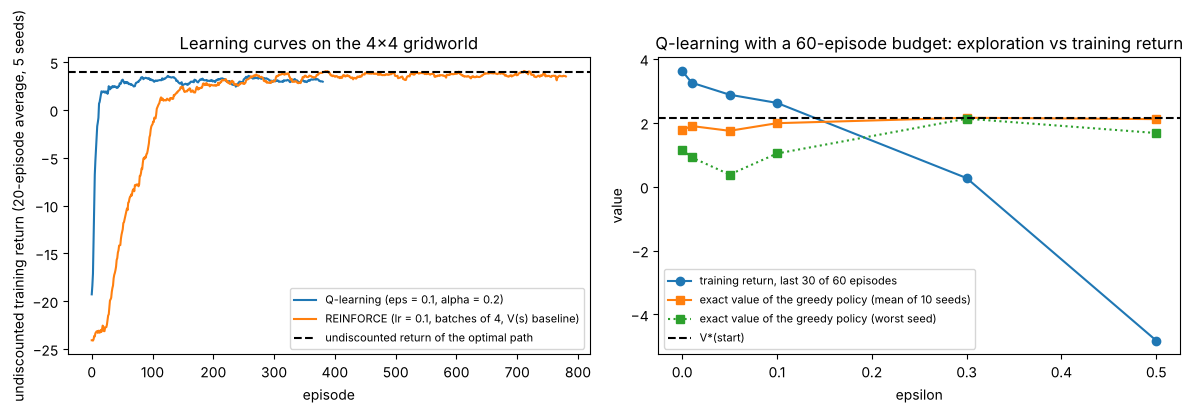

In [21]:
def softmax(z):
    z = z - np.max(z); e = np.exp(z); return e / e.sum()

def value_iteration_env(env, tol=1e-10):
    V = np.zeros(env.n_states)
    for n in range(1, 100_000):
        Q = env.R + env.gamma * np.einsum("sat,t->sa", env.P, V); V_new = Q.max(axis=1)
        if np.abs(V_new - V).max() < tol:
            V = V_new; break
        V = V_new
    Q = env.R + env.gamma * np.einsum("sat,t->sa", env.P, V)
    return V, Q.argmax(axis=1), n

def exact_value_of(env, policy):
    # exact V^pi of a deterministic policy by the linear solve (the honest yardstick)
    S = env.n_states; idx = np.arange(S)
    return np.linalg.solve(np.eye(S) - env.gamma * env.P[idx, policy], env.R[idx, policy])

def q_learning(env, n_episodes, alpha, eps, rng, max_steps=200):
    Q = np.zeros((env.n_states, env.n_actions)); rets = np.zeros(n_episodes)
    for ep in range(n_episodes):
        s = env.start; total = 0.0
        for _ in range(max_steps):
            a = int(rng.integers(env.n_actions)) if rng.random() < eps else int(np.argmax(Q[s]))
            s2, r, done = env.step(s, a, rng); total += r
            Q[s, a] += alpha * (r + (0.0 if done else env.gamma * Q[s2].max()) - Q[s, a]); s = s2
            if done: break
        rets[ep] = total
    return Q, rets

def reinforce(env, n_episodes, lr, rng, horizon=25, batch=4, baseline=True):
    # tabular softmax policy; gradient accumulated over `batch` episodes, learned V(s) baseline;
    # common gamma^t-free variant: step t's score is weighted by G_t - V(s_t) (the exact gradient would multiply by gamma**t)
    theta = np.zeros((env.n_states, env.n_actions)); V_b = np.zeros(env.n_states); rets = np.zeros(n_episodes)
    grad = np.zeros_like(theta)
    for ep in range(n_episodes):
        s = env.start; traj = []
        for _ in range(horizon):
            p = softmax(theta[s]); a = int(rng.choice(env.n_actions, p=p))
            s2, r, done = env.step(s, a, rng); traj.append((s, a, r, p)); s = s2
            if done: break
        G = 0.0; returns = []
        for (_, _, r, _) in reversed(traj):
            G = r + env.gamma * G; returns.append(G)
        returns = returns[::-1]
        for (s, a, r, p), G in zip(traj, returns):
            adv = G - (V_b[s] if baseline else 0.0)
            grad[s] += adv * (np.eye(env.n_actions)[a] - p)
        if (ep + 1) % batch == 0:
            theta += lr * grad / batch; grad = np.zeros_like(theta)
        for (s, a, r, p), G in zip(traj, returns):
            V_b[s] += 0.1 * (G - V_b[s])
        rets[ep] = sum(r for (_, _, r, _) in traj)
    return theta, rets

def smooth(x, w=20): return np.convolve(x, np.ones(w) / w, mode="valid")

# 1. the exact answer
V_star, pi_star, n_sweeps = value_iteration_env(grid)
print(f"value iteration: {n_sweeps} sweeps, V*(start) = {V_star[grid.start]:.3f}  (undiscounted return of the optimal path: 4)")
print(np.array(list(grid.policy_string(pi_star))).reshape(4, 4))

# 2. Q-learning and REINFORCE over several seeds, judged by the EXACT value of their greedy policies
n_seeds = 5
q_curves, r_curves, q_vals, r_vals = [], [], [], []
for seed in range(n_seeds):
    Q, rets = q_learning(grid, 400, alpha=0.2, eps=0.1, rng=np.random.default_rng(seed))
    q_curves.append(rets); q_vals.append(exact_value_of(grid, Q.argmax(axis=1))[grid.start])
    theta, rets = reinforce(grid, 800, lr=0.1, rng=np.random.default_rng(seed))
    r_curves.append(rets); r_vals.append(exact_value_of(grid, theta.argmax(axis=1))[grid.start])
print(f"\nexact value of the learned greedy policy at the start (optimum {V_star[grid.start]:.3f}):")
print(f"  Q-learning (400 episodes): {np.round(q_vals, 3)}  mean {np.mean(q_vals):.3f}")
print(f"  REINFORCE  (800 episodes): {np.round(r_vals, 3)}  mean {np.mean(r_vals):.3f}")
print(f"  training return, last 100 episodes: Q-learning {np.mean([c[-100:] for c in q_curves]):.2f}, REINFORCE {np.mean([c[-100:] for c in r_curves]):.2f}")

# 2b. what makes REINFORCE work here? two ablations on the same five seeds
abl_a = [exact_value_of(grid, reinforce(grid, 400, lr=0.05, rng=np.random.default_rng(seed), horizon=40, batch=1)[0].argmax(axis=1))[grid.start]
         for seed in range(n_seeds)]
abl_b = [exact_value_of(grid, reinforce(grid, 800, lr=0.1, rng=np.random.default_rng(seed), baseline=False)[0].argmax(axis=1))[grid.start]
         for seed in range(n_seeds)]
print(f"  REINFORCE ablation, one update per episode, lr 0.05, horizon 40: {np.round(abl_a, 3)}")
print(f"  REINFORCE ablation, batches of 4, horizon 25, NO baseline:       {np.round(abl_b, 3)}")
print(f"  (a policy that never reaches the goal is worth -1/(1 - gamma) = {-1 / (1 - grid.gamma):.0f})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(smooth(np.mean(q_curves, axis=0)), label="Q-learning (eps = 0.1, alpha = 0.2)")
ax1.plot(smooth(np.mean(r_curves, axis=0)), label="REINFORCE (lr = 0.1, batches of 4, V(s) baseline)")
ax1.axhline(4.0, color="k", ls="--", label="undiscounted return of the optimal path")
ax1.set_xlabel("episode"); ax1.set_ylabel("undiscounted training return (20-episode average, 5 seeds)")
ax1.set_title("Learning curves on the 4x4 gridworld"); ax1.legend(fontsize=8)

# 3. sensitivity: gamma (exact) and epsilon (Q-learning with a short budget, exact value of the greedy policy)
print("\nsensitivity to gamma (value iteration):")
for g in [0.5, 0.8, 0.9, 0.95, 0.99]:
    env_g = GridWorld(4, 4, start=(3, 0), goal=(0, 3), walls=[(1, 1), (2, 2)], pits=[(0, 2)], slip=0.1, gamma=g)
    V_g, pi_g, n_g = value_iteration_env(env_g)
    print(f"  gamma = {g:4.2f}: V*(start) = {V_g[grid.start]:7.3f}, {n_g:3d} sweeps, policy {env_g.policy_string(pi_g)}")
epsilons = [0.0, 0.01, 0.05, 0.1, 0.3, 0.5]
print("\nsensitivity to epsilon (Q-learning, 60 episodes, 10 seeds):")
mean_train, mean_exact, min_exact = [], [], []
for eps in epsilons:
    tr, ex_ = [], []
    for seed in range(10):
        Q, rets = q_learning(grid, 60, alpha=0.2, eps=eps, rng=np.random.default_rng(seed))
        tr.append(rets[-30:].mean()); ex_.append(exact_value_of(grid, Q.argmax(axis=1))[grid.start])
    mean_train.append(np.mean(tr)); mean_exact.append(np.mean(ex_)); min_exact.append(np.min(ex_))
    long_ = [exact_value_of(grid, q_learning(grid, 400, alpha=0.2, eps=eps, rng=np.random.default_rng(seed))[0].argmax(axis=1))[grid.start]
             for seed in range(5)]
    print(f"  eps = {eps:4.2f}: training return (last 30) {np.mean(tr):6.2f}   exact value of greedy policy: mean {np.mean(ex_):6.3f}, "
          f"worst seed {np.min(ex_):6.3f}, seeds within 0.05 of optimum {sum(v > V_star[grid.start] - 0.05 for v in ex_)}/10"
          f"   | with 400 episodes (5 seeds): worst seed {np.min(long_):6.3f}")
ax2.plot(epsilons, mean_train, "o-", label="training return, last 30 of 60 episodes")
ax2.plot(epsilons, mean_exact, "s-", label="exact value of the greedy policy (mean of 10 seeds)")
ax2.plot(epsilons, min_exact, "s:", label="exact value of the greedy policy (worst seed)")
ax2.axhline(V_star[grid.start], color="k", ls="--", label="V*(start)")
ax2.set_xlabel("epsilon"); ax2.set_ylabel("value"); ax2.set_title("Q-learning with a 60-episode budget: exploration vs training return"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Score

In [22]:
summary()


Score: 69/69 checks passed  🎉
